# Day 1 (sessions 1A + 1B): Python-to-ML baseline

**Estimated core time:** 60 minutes  
**Dataset:** `data/customer_churn.csv`  
**Outcome:** build and evaluate your first leakage-safe Python classifier

This notebook deliberately contains empty code cells. Write the code yourself; ask Codex for a hint when you need one.

## Why this matters

A large share of applied ML interviews is not about exotic algorithms. It is about whether you can move safely from a table to a defensible baseline: inspect the data, define predictors and target, split correctly, preprocess without leakage, fit a model, and explain its performance.

You already know the statistical ideas. Today is about translating them into Python objects and scikit-learn's workflow.

## Learning objectives

By the end, you should be able to:

1. Read and inspect a pandas `DataFrame` using its shape, dtypes, selections, and summaries.
2. Translate a few familiar dplyr operations into pandas.
3. Produce ggplot-style charts with plotnine.
4. Create a stratified train/test split and explain why splitting comes before learned preprocessing.
5. Fit a dummy baseline and a preprocessing-plus-logistic-regression pipeline.
6. distinguish `predict` from `predict_proba` and interpret several classification metrics.

## R-to-Python bridge

| R / tidyverse | Python today |
|---|---|
| `library(pandas)` idea | `import pandas as pd` |
| `readr::read_csv(...)` | `pd.read_csv(...)` |
| `dim(df)` | `df.shape` (an attribute, so no parentheses) |
| `glimpse(df)` | `df.info()` and `df.dtypes` |
| `df |> filter(...)` | `df.loc[boolean_condition]` |
| `select(df, a, b)` | `df[["a", "b"]]` |
| `mutate(df, z = ...)` | assignment or `df.assign(z=...)` |
| `group_by(...) |> summarise(...)` | `df.groupby(...).agg(...)` |
| `ggplot2` | `plotnine` |
| `factor` | categorical/string columns plus an encoder for ML |

Two Python details to watch:

- Indexing starts at zero.
- `df.shape` and `df.dtypes` are attributes; `df.head()` and `df.info()` are methods.

## Suggested pacing

- 0–10 min: setup and structural audit
- 10–23 min: pandas and plotnine
- 23–33 min: predictors, target, and splitting
- 33–52 min: dummy and logistic-regression models
- 52–60 min: debugging, retrieval, and interview explanations

If a task takes longer, prioritize understanding over finishing every optional detail.

## Task 1 — Import and load the data

Import the following names, then load the CSV into a variable called `churn`:

- `pandas` as `pd`
- `ggplot`, `aes`, `geom_histogram`, `geom_bar`, `labs`, and `theme_minimal` from `plotnine`
- scikit-learn tools introduced later: `train_test_split`, `DummyClassifier`, `LogisticRegression`, `SimpleImputer`, `StandardScaler`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline`, and the five metric functions used in Task 8

Use the relative path `data/customer_churn.csv`. Display the first five rows.

**Self-check:** the object should be a pandas `DataFrame` with 2,500 rows and 12 columns.

A typical import pattern is:

```python
import package_name as short_name
from package.submodule import ObjectName
```

In [ ]:
import pandas as pd

from plotnine import ggplot, aes, geom_histogram, labs, theme_minimal, geom_bar

from sklearn.model_selection import train_test_split

from sklearn.dummy import DummyClassifier

from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import StandardScaler

from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression



churn = pd.read_csv('data/customer_churn.csv')
churn.head()

## Task 2 — Structural audit and output prediction

Before running anything, predict which expressions below return a single number, a tuple, a pandas `Series`, or a `DataFrame`:

```python
churn.shape
churn["churned"]
churn[["age", "tenure_months"]]
churn["churned"].mean()
```

Then use Python to:

1. Show `churn.shape` and `churn.dtypes`.
2. Calculate target prevalence as the mean of `churned`.
3. Calculate missing values per column and sort them from most to least.
4. Confirm whether `customer_id` is unique.

**Self-check:** prevalence should be close to 0.24. Three predictor columns contain missing values.

Answers:
churn.shape is predicted to return a tuple
churn["churned"] will return the colum churned from the dataset as pandas Series
chrun[['age', 'tenure_month']] will return a DatFrame contain just the two selected columns
churn['churned'].mean() will show the mean of that columns, so it will return a single digit

In [ ]:
print(churn.shape)
print(churn.dtypes)
print("Target prevalence:", churn['churned'].mean())

(2500, 12)
customer_id                str
age                    float64
household_size           int64
tenure_months            int64
contract                   str
internet_service           str
payment_method             str
monthly_charge_eur     float64
monthly_usage_hours    float64
support_calls_6m         int64
late_payments_12m        int64
churned                  int64
dtype: object
target prevalence: 0.2376


In [25]:
# Calculate the number of missing values in each column, sort them

missing_values = churn.isnull().sum().sort_values(ascending=False)
missing_values

monthly_usage_hours    107
age                     83
payment_method          48
customer_id              0
household_size           0
tenure_months            0
contract                 0
internet_service         0
monthly_charge_eur       0
support_calls_6m         0
late_payments_12m        0
churned                  0
dtype: int64

In [ ]:
# confirm wheather customer_id is unique
print("Number of unique customer IDs:", churn['customer_id'].nunique())

Number of unique customer IDs: 2500


it is unique as the dataset has 2500 length and the nunique returned that number

## Task 3 — Translate a focused dplyr operation

Create a new `DataFrame` called `high_contact_monthly` containing customers who:

- have a monthly contract, and
- made at least three support calls.

Keep only `customer_id`, `tenure_months`, `monthly_charge_eur`, and `support_calls_6m`. Add `annual_charge_eur` as twelve times the monthly charge, and sort from highest to lowest annual charge.

Useful pieces:

```python
frame.loc[condition, ["column_a", "column_b"]]
frame.assign(new_column=...)
frame.sort_values("column", ascending=False)
```

Use parentheses around each boolean condition and combine them with `&`. Python/pandas does not use R's scalar `&&` for element-wise filtering.

**Acceptance check:** every retained row must have `contract == "monthly"` and `support_calls_6m >= 3`.

In [28]:
churn.head()

,customer_id,age,household_size,tenure_months,contract,internet_service,payment_method,monthly_charge_eur,monthly_usage_hours,support_calls_6m,late_payments_12m,churned
0,CH00001,49.0,2,61,monthly,none,card,69.58,56.8,2,1,1
1,CH00002,52.0,3,8,one_year,dsl,electronic_check,72.86,44.4,2,0,0
2,CH00003,37.0,1,60,monthly,fiber,card,58.54,49.3,0,0,0
3,CH00004,41.0,3,71,two_year,dsl,card,44.75,37.5,2,2,0
4,CH00005,37.0,2,6,monthly,dsl,bank_transfer,41.27,59.7,2,0,0


In [44]:
high_contact_monthly = churn.loc[(churn['contract'] == 'monthly')& (churn['support_calls_6m'] >= 3), ['customer_id','contract', 'tenure_months', 'monthly_charge_eur', 'support_calls_6m']]
high_contact_monthly['annual_charge_eur'] = high_contact_monthly['monthly_charge_eur'] * 12


# Acceptance criteria:
print(high_contact_monthly['contract'].unique())
print(high_contact_monthly['support_calls_6m'].min() >= 3)

<StringArray>
['monthly']
Length: 1, dtype: str
True


## Task 4 — Grouped summary

Create a summary by `contract` with:

- `n`: number of rows
- `churn_rate`: mean of `churned`
- `mean_monthly_charge`: mean of `monthly_charge_eur`
- `median_tenure`: median of `tenure_months`

Sort from highest to lowest churn rate and display the result.

The named-aggregation pattern is:

```python
frame.groupby("group_column").agg(
    new_name=("source_column", "aggregation"),
)
```

**Self-check:** the result has three rows, one per contract type. Ask yourself whether the grouping variable is an index or a normal column, and how `reset_index()` changes that.

In [49]:
churn.groupby('contract').agg(
    n=('customer_id', 'count'),
    churn_rate=('churned', 'mean'),
    mean_monthly_charge=('monthly_charge_eur', 'mean'),
    median_tenure=('tenure_months', 'median')
).sort_values(by='churn_rate', ascending=False)

,n,churn_rate,mean_monthly_charge,median_tenure
contract,,,,
monthly,1376,0.319041,68.199048,37.0
one_year,716,0.160615,69.010824,37.0
two_year,408,0.098039,69.078897,39.0


the grouping variable is not a normal column, but reset_index() fixes that and includes the grouping variables as a normal variable in the resulting dataframe

## Task 5 — Two plotnine charts

Create both plots:

1. A histogram of `monthly_charge_eur` with 30 bins.
2. A proportional bar chart of `contract` filled by a readable churn label such as `"stayed"` / `"churned"`.

For the second chart, first create a copy or use `assign` to add the readable label. In plotnine, proportional bars use `geom_bar(position="fill")`.

Minimal grammar reminder:

```python
(
    ggplot(a_dataframe, aes(x="x_column"))
    + geom_histogram(bins=20)
    + labs(title="...", x="...", y="...")
    + theme_minimal()
)
```

Add clear titles and axis labels. After viewing the charts, write down one pattern you notice—without claiming causation.

Matplotlib is building the font cache; this may take a moment.


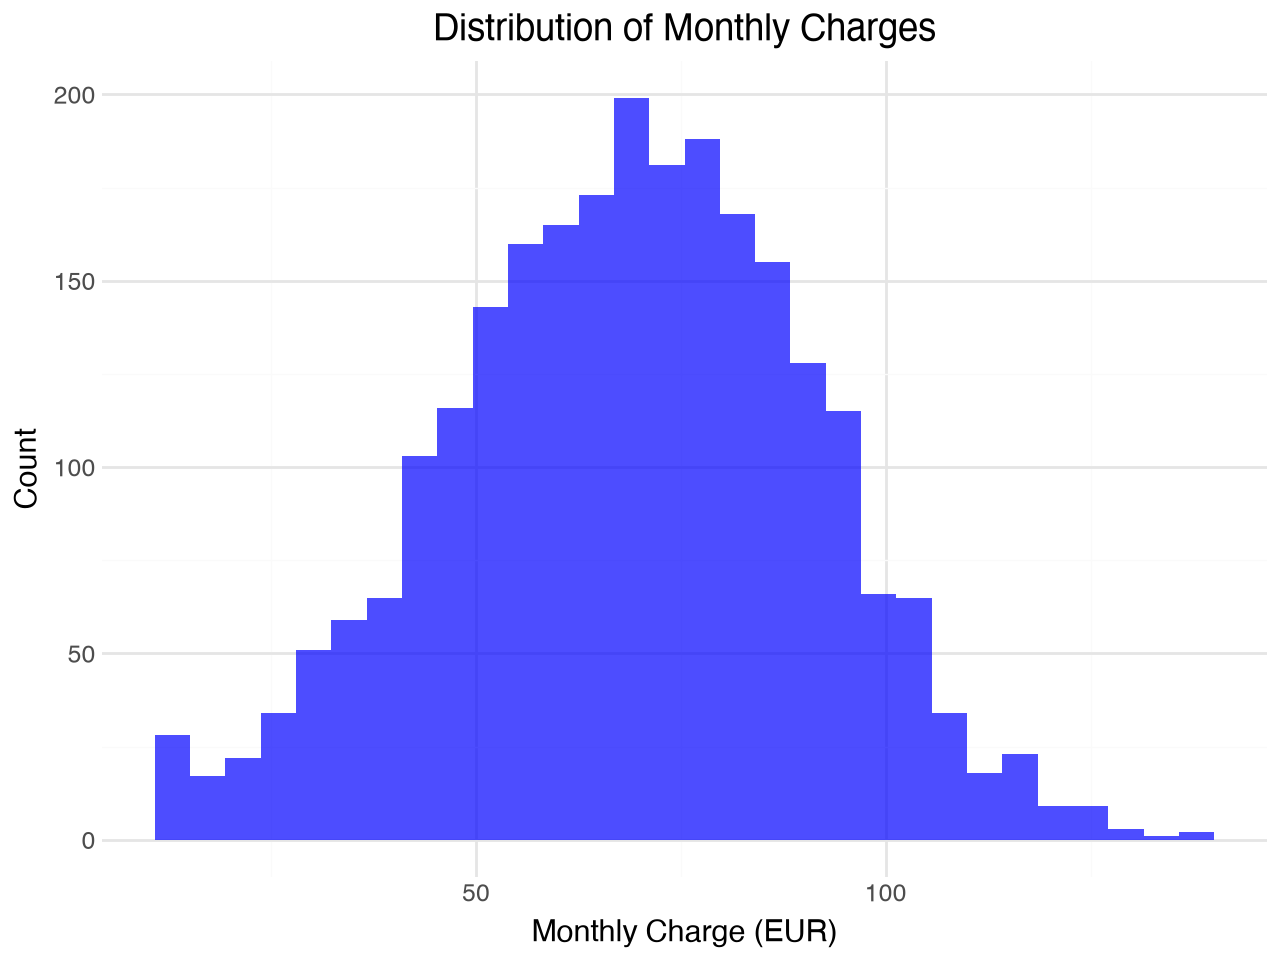

In [52]:
(
ggplot(churn, aes(x='monthly_charge_eur'))
+ geom_histogram(bins=30, fill='blue', alpha=0.7)
+ labs(title='Distribution of Monthly Charges', x='Monthly Charge (EUR)', y='Count')
+ theme_minimal()
)

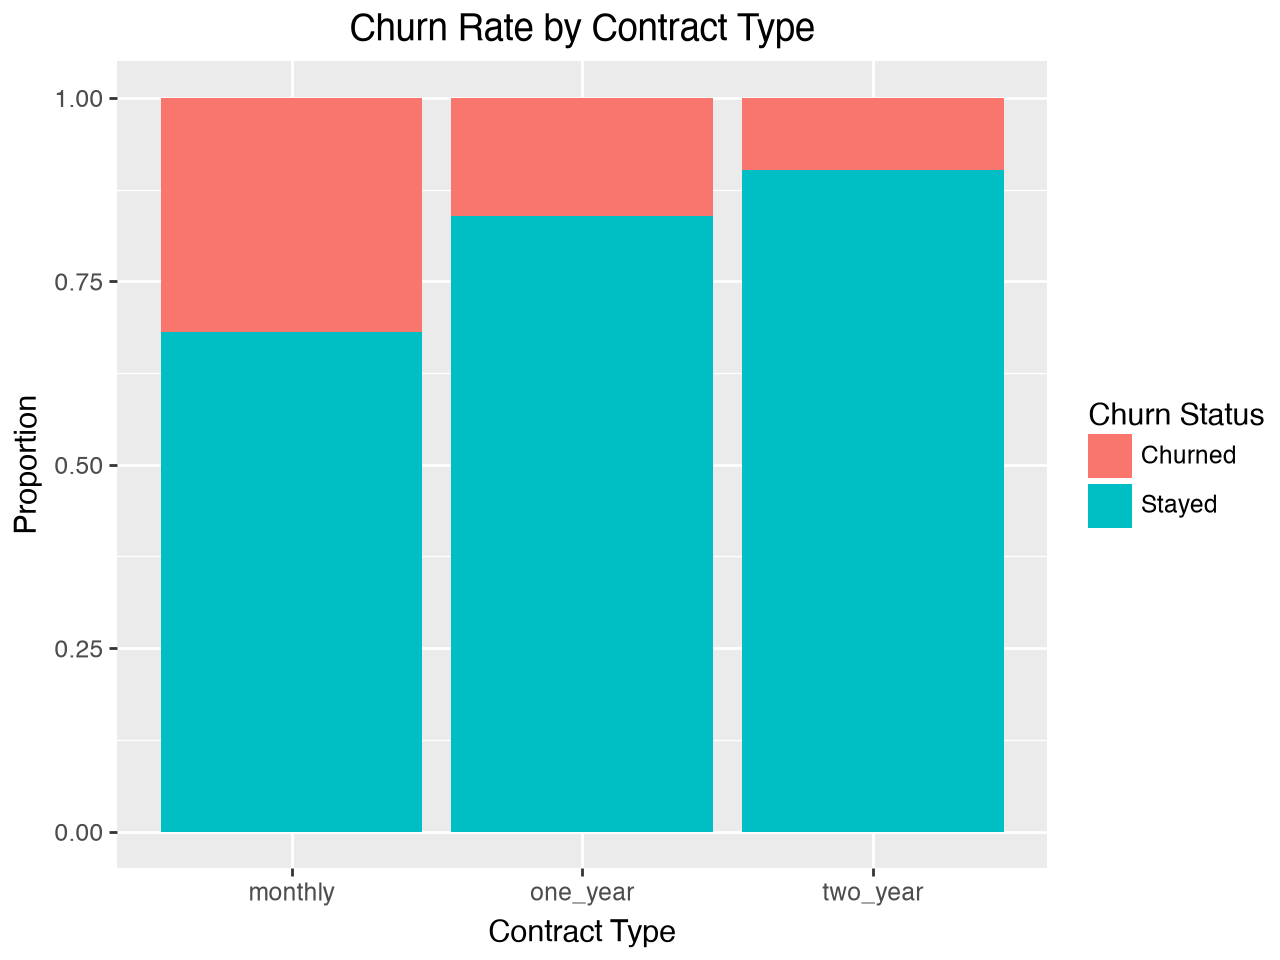

In [69]:
churn["churned_readable"] = churn["churned"].map({0: "Stayed", 1: "Churned"})

(
    ggplot(churn, aes(x = 'contract', fill = 'churned_readable'))
    + geom_bar(position = 'fill')
    + labs(title = 'Churn Rate by Contract Type', x = 'Contract Type', fill = 'Churn Status', y = 'Proportion')
)

## Modeling checkpoint

From here on, keep three roles separate:

- **`X`:** predictor columns supplied to the model
- **`y`:** target values the model tries to predict
- **identifier:** useful for tracing rows, but normally not a meaningful predictor

A scikit-learn estimator generally learns with `fit(X_train, y_train)` and applies what it learned with `predict(X_new)` or `predict_proba(X_new)`.

## Task 6 — Define predictors, target, and feature roles

Create:

- `y` from `churned`
- `X` by dropping `churned` and `customer_id`
- `numeric_features` as a Python list of the seven numeric predictor names
- `categorical_features` as a Python list of the three categorical predictor names

Print or inspect the shapes and lists.

**Predict before running:** what should `X.shape` and `y.shape` be?

**Self-check:** `X` should have 10 columns. Explain why `customer_id` was excluded even though it is numeric-looking information to a computer once encoded.

In [84]:
y = churn['churned']
x = churn.drop(columns=['customer_id', 'churned', 'churned_readable'])
numeric_features = x.select_dtypes(include=['int64', 'float64']).columns
categorical_features = x.select_dtypes(include=['str']).columns

print(y.shape)
print(x.shape)
print(numeric_features.shape)
print(categorical_features.shape)

(2500,)
(2500, 10)
(7,)
(3,)


X has 10 columns, customer id was excluded because it is a 1 to 1 mapping for each observation in the dataset. no usefull information for the model is there so it is excluded. the model should not simply learn id 19 is churned. 

## Task 7 — Make a stratified train/test split

Split `X` and `y` with:

- 20% test data
- `random_state=42`
- `stratify=y`

Name the four outputs `X_train`, `X_test`, `y_train`, and `y_test`.

Then compare the positive-class prevalence in `y_train` and `y_test`.

API reminder:

```python
train_test_split(X, y, test_size=..., random_state=..., stratify=...)
```

**Predict before running:** expected row counts are 2,000 for training and 500 for testing. Why is approximate class balance in both sets useful here?

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2000, 10)
(500, 10)
(2000,)
(500,)


In [94]:
# Inspecth the class balance in test and train:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

churned
0    0.7625
1    0.2375
Name: proportion, dtype: float64
churned
0    0.762
1    0.238
Name: proportion, dtype: float64


These are pretty close, so the test and train show a similar proportion of predictors, which is great.

## Task 8 — Establish a dummy baseline

Fit a `DummyClassifier(strategy="most_frequent")` on the training data. Generate:

- predicted classes for the test data
- positive-class probabilities for the test data

Calculate accuracy, precision, recall, F1, and ROC AUC.

Useful metric signatures:

```python
accuracy_score(y_true, predicted_class)
precision_score(y_true, predicted_class, zero_division=0)
recall_score(y_true, predicted_class)
f1_score(y_true, predicted_class)
roc_auc_score(y_true, positive_class_probability)
```

For a binary classifier, positive-class probabilities normally come from column 1:

```python
estimator.predict_proba(X_new)[:, 1]
```

**Interpretation requirement:** identify which metrics make this baseline look acceptable and which expose its uselessness. Why must a real model beat it?

In [108]:
dummy_model = DummyClassifier(strategy='most_frequent')

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

dummy_probabilities = dummy_model.predict_proba(X_test)[:, 1]

In [110]:
# Test this dummy model:
dummy_accuracy = accuracy_score(y_test, dummy_predictions)
dummy_precision = precision_score(y_test, dummy_predictions, zero_division=0)
dummy_recall = recall_score(y_test, dummy_predictions)
dummy_f1 = f1_score(y_test, dummy_predictions)
dummy_roc_auc = roc_auc_score(y_test, dummy_probabilities)

print(dummy_accuracy)
print(dummy_precision)
print(dummy_recall)
print(dummy_f1)
print(dummy_roc_auc)

0.762
0.0
0.0
0.0
0.5


Accuracy = the model is correct 76% pf the times, as it predicts always the most frequent class, which is 0 = stayed, it is simply the proportion of 0 in the dataset. 

Precision (if there is a 1 in the prediction, how many of these where correct) = Since the model can only predict 0, it never got a 1 correctly

Recall (if there is a 1 in the data, how many did the model catch) = same answer as above, since the model cannot give out 1, recall is 0

F1 = is the combined score of precision and recall. since both are 0, f1 is 0 too.

ROC AUC = (this should be close to 1) = 0.5 means random guessing

## Task 9 — Build a preprocessing and logistic-regression pipeline

Build two preprocessing pipelines:

- Numeric: median imputation, then standardization.
- Categorical: most-frequent imputation, then one-hot encoding with unknown categories ignored.

Combine them in a `ColumnTransformer`, then create a final `Pipeline` ending in `LogisticRegression(max_iter=1000)`.

Structural reminders:

```python
Pipeline([
    ("first_step_name", some_transformer),
    ("final_step_name", some_estimator),
])

ColumnTransformer([
    ("numeric", numeric_transformer, numeric_column_names),
    ("categorical", categorical_transformer, categorical_column_names),
])
```

Useful constructor options:

```python
SimpleImputer(strategy="median")
SimpleImputer(strategy="most_frequent")
OneHotEncoder(handle_unknown="ignore")
StandardScaler()
LogisticRegression(max_iter=1000)
```

Call the final object `logistic_pipeline`.

**Concept check:** identify which steps learn quantities from data. Those steps must be fitted using training data only.

In [125]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())

])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)

])

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])



## Task 10 — Fit, predict, evaluate, and compare

Fit `logistic_pipeline` on `X_train` and `y_train`. On `X_test`:

1. Generate class predictions.
2. Generate positive-class probabilities.
3. Calculate the same five metrics as for the dummy model.
4. Put the dummy and logistic-regression results into a small comparison `DataFrame` with one row per model.
5. Inspect the transformed training-matrix shape through the fitted preprocessing step.

You can access a named pipeline step with:

```python
fitted_pipeline.named_steps["step_name"]
```

**Shape checks:**

- class predictions: `(500,)`
- positive probabilities: `(500,)`
- transformed training data: 2,000 rows; reason out the likely number of columns from seven numeric features and the one-hot levels

**Interpretation requirement:** state which model you prefer and why. Do not say only “the score is higher”; name the metric and what it means for churn prediction.

In [134]:
model1 = logistic_pipeline.fit(X_train, y_train)

# Get the model prediction 
model1_predictions = model1.predict(X_test)

# Get the positive class probabilities for the test set
model1_pos_probabilities = model1.predict_proba(X_test)[:, 1]

In [168]:
model1_accuracy = accuracy_score(y_test, model1_predictions)
model1_precision = precision_score(y_test, model1_predictions, zero_division=0)
model1_recall = recall_score(y_test, model1_predictions)
model1_f1 = f1_score(y_test, model1_predictions)
model1_roc_auc = roc_auc_score(y_test, model1_pos_probabilities)


results_df = pd.DataFrame({
    "Model": ["Dummy", "Model 1"],
    "Accuracy": [dummy_accuracy, model1_accuracy],
    "Precision": [dummy_precision, model1_precision],
    "Recall": [dummy_recall, model1_recall],
    "F1 Score": [dummy_f1, model1_f1],
    "ROC AUC": [dummy_roc_auc, model1_roc_auc]
})

print(results_df)

     Model  Accuracy  Precision    Recall  F1 Score   ROC AUC
0    Dummy     0.762   0.000000  0.000000  0.000000  0.500000
1  Model 1     0.808   0.661972  0.394958  0.494737  0.819052


In [150]:
# Task 5:
print(logistic_pipeline.named_steps.keys())

logistic_pipeline.named_steps["preprocessor"].transform(X_train).shape


dict_keys(['preprocessor', 'model'])


(2000, 16)

The model 1 is slightly better, it definitely outperforms the dummy model, which was expected.

## Task 11 — Debug an unsafe ML workflow

An AI assistant proposes this code:

```python
encoded = pd.get_dummies(churn)
X = encoded.drop(columns="churned")
y = encoded["churned"]

X = X.fillna(X.mean())
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

model = LogisticRegression()
model.fit(X_test, y_test)
score = model.score(X_test, y_test)
```

Without copying your previous solution blindly:

1. Identify at least four statistical or coding problems.
2. Write a corrected workflow using the objects you created above.
3. Explain which line in the safe workflow prevents each major problem.

Look especially for identifier use, preprocessing before splitting, absent stratification, fitting on the wrong partition, and evaluating on data used for fitting.

ID column was not revomed from X 
the categorical values are simply set to true and false, then there mean is taken to fill NA values. this makes the variable numeric... 
no scaling 
no test train split proportion was defined,. 
model is trained and evaluated on test data. 

In [ ]:
X - 

age                                45.117087
household_size                      2.514400
tenure_months                      36.859600
monthly_charge_eur                 68.575132
monthly_usage_hours                40.015127
                                     ...    
internet_service_fiber              0.500000
internet_service_none               0.114000
payment_method_bank_transfer        0.348800
payment_method_card                 0.378400
payment_method_electronic_check     0.253600
Length: 2517, dtype: float64

## Retrieval practice — Task 12 (less guidance)

Without referring to Task 4's template, produce a summary by `internet_service` containing row count, churn rate, and mean monthly charge, sorted by churn rate.

Then use `type(...)` and `.shape` to inspect:

- `X_train`
- `y_train`
- the logistic model's class predictions
- its probability matrix before selecting column 1

Explain why the probability matrix has two columns but the class-prediction array has one dimension.

In [160]:
internet_summary = churn.groupby('internet_service').agg(
    n=('customer_id', 'count'),
    churn_rate=('churned', 'mean'),
    mean_monthly_charge=('monthly_charge_eur', 'mean')
).sort_values(by='churn_rate', ascending=False)

print(internet_summary.shape)
print(internet_summary.dtypes)
print(internet_summary)

(3, 3)
n                        int64
churn_rate             float64
mean_monthly_charge    float64
dtype: object
                     n  churn_rate  mean_monthly_charge
internet_service                                       
fiber             1250    0.296000            79.837264
dsl                965    0.200000            62.266974
none               285    0.108772            40.539018


In [166]:
print(X_train.shape)
print(X_train.dtypes)
print(y_train.shape)
print(y_train.dtypes)

print(model1_predictions.shape)
print(model1_predictions.dtype)

(2000, 10)
age                    float64
household_size           int64
tenure_months            int64
contract                   str
internet_service           str
payment_method             str
monthly_charge_eur     float64
monthly_usage_hours    float64
support_calls_6m         int64
late_payments_12m        int64
dtype: object
(2000,)
int64
(500,)
int64


## Interview questions

Answer these aloud or add a markdown cell beneath this one:

1. Why do we split before fitting imputers, scalers, or encoders?
2. Why can accuracy look good for a useless churn model?
3. What is the difference between `predict` and `predict_proba`?
4. Logistic regression is familiar from inference. What changes when the primary goal is out-of-sample prediction rather than coefficient inference?

A strong answer names the mechanism, not just a rule such as “because leakage is bad.”

1. Because we then train the imputer scaler and encoders on the train data, and can use their values on the test data later. preventing leakage
2. because accuracy simply shoes the proportion of correctly guessed classes. if one class dominates and our model predicts only that class, we get a high accuracy for a uselelss model
3. predict does predict the class, while proba predicts the probability that it is a certain class
4. the primary goal here in machine learning was to predict the classes correctly. coefficient inference is used when we want to understand the underlying relationship better and care not only about correct classificaiton.

## Self-check and reflection

Before calling this lesson complete, record:

- Confidence from 1–5:
    2: My machine learning skills are off... this is the first time i heard about the preprocessing pipelines and applied them like this. 
- Hardest point:
    - Proprcessing pipeline, and synatax of model objects, after the model is fit. need repitiion to know hwere to write the regressor, and so on... 
- One thing you can now explain:
    - I understand model metrics much better now: Accuracy, Recall, Precision, F1, ROC AUC
- One topic that deserves repetition:
    - Preprocessing pipeline writind
- Did the core work take roughly 60 minutes?
    - no much longer, but with breaks, so ruffly 3-4 hours for me... 

When you are finished, tell Codex you completed the notebook and optionally ask for a review. Completion should only be recorded after your attempt.

## Optional extension — threshold preview (outside the 60 minutes)

The logistic model's default class prediction usually uses a probability threshold of 0.5.

Create new class predictions using thresholds 0.30, 0.50, and 0.70. For each threshold, calculate precision and recall and put the results in a table.

Before running, predict the direction in which precision and recall should move as the threshold increases. This previews session 1C.

## Finish line

You have completed the core lesson when you can explain the path:

**CSV → DataFrame audit → X/y → stratified split → training-only preprocessing → baseline → logistic model → probabilities → metrics → interpretation**

XGBoost enters on Day 3, after this evaluation foundation is secure.